# Автоматическая атрибуция авторства текстов блогов на основе методов машинного обучения

# Постановка задачи (Business Understanding)

**Цель проекта**: разработать модель машинного обучения для атрибуции авторства текстов блогов и исследовать эффективность лексических и стилометрических признаков при решении данной задачи. 

**Задача**: многоклассовая классификация, 15 классов (= 15 авторов). Модель должна предсказать автора по текстовым признакам.

* объект — текст блога;
* целевая переменная — id автора;
* классы — авторы;

**Данные**: https://www.kaggle.com/datasets/rtatman/blog-authorship-corpus/data

Это корпус авторских блогов, он состоит из постов 19 320 блогеров, собранных на сайте blogger.com в августе 2004 года. Корпус включает в себя 681 288 постов и более 140 миллионов слов. В этом проекте используется выборка из 15 авторов с самым большим количеством текстов. При этом количество текстов на каждого автора — 883 + отобраны тексты длиной не менее 50 слов (подробнее о создании выборки можно прочитать в следующих разделах).	

**Общая схема:**

создание выборки → предобработка текста → векторизация (разные модели и параметры) → классификация (разные модели и параметры) → предсказание автора → подсчет метрик → анализ *→ предсказание пола автора

**Почему это полезно и актуально**

Атрибуцией авторства часто занимаются в компьютерной лингвистике, но чаще она проводится на художественной литературе. Кроме того, определение автора текста необходимо в юридических целях. Для блогов (и в принцнипе для любых текстов на просторе интернета) эта задача выглядит особенно актуально, потому что, во-первых, такие тексты часто имеют индивидуальный стиль (потому что это не какой-нибудь формальный текст, написанный по шаблону, а обычно что-то личное + часто есть ярко выраженные черты, например, один автор все пишет капслоком и использует много восклицательных знаков, а другой наоборот все пишет без загланых букв и точек), а во-вторых, такой интструмент может быть полезен для выявления авторов анонимных публикаций (например, если автор где-то пишет анонимно, а где-то от своего имени и мы хотим понять, это один и тот же человек или нет).

**Почему ML хорошо подходит для такой задачи**

Есть стилометрия, которая предлагает количественные признаки для описания авторского стиля, но эти признаки не создают готовое правило классификации. Машинное обучение позволяет сочетать множество признаков и выявить закономерности, которые позволят отличить тексты авторов друг от друга.

# Data Understanding

In [1]:
# Базовые библиотеки для работы с данными

import os
import re
import numpy as np
import pandas as pd

# Визуализация

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Базовые настройки

# Для воспроизводимости результатов
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Настройки отображения таблиц
pd.set_option("display.max_columns", None) # это чтобы показывать все столбцы датафрейма
pd.set_option("display.max_colwidth", 120) # это максимум символов, которые будут показаны в одной ячейке таблицы

# Стиль графиков
sns.set_style("whitegrid") # это включает стиль белого фона с сеткой
plt.rcParams["figure.figsize"] = (10, 5) # это задает размер всех графиков matplotlib

## Загрузка и предобработка данных

In [85]:
# Читаем датасет
df = pd.read_csv("blogtext.csv", engine="python", on_bad_lines="skip") # более гибкий парсер, иначе ломается на некоторых строках + пропускаем битые строки

print("Размер исходного датасета:", df.shape)
df.head()

Размер исходного датасета: (681241, 7)


,id,gender,age,topic,sign,date,text
0,2059027,male,15,Student,Leo,"14,May,2004","Info has been found (+/- 100 pages, and 4.5 MB of .pdf files) Now i have to wait untill our team leader h..."
1,2059027,male,15,Student,Leo,"13,May,2004",These are the team members: Drewes van der Laag urlLink mail Ruiyu Xie u...
2,2059027,male,15,Student,Leo,"12,May,2004",In het kader van kernfusie op aarde: MAAK JE EIGEN WATERSTOFBOM How to build an H-Bomb From: ascott@ta...
3,2059027,male,15,Student,Leo,"12,May,2004",testing!!! testing!!!
4,3581210,male,33,InvestmentBanking,Aquarius,"11,June,2004",Thanks to Yahoo!'s Toolbar I can now 'capture' the URLs of popups...which means now I can show you some...


Первичный анализ данных

In [86]:
# Названия столбцов
df.columns

Index(['id', 'gender', 'age', 'topic', 'sign', 'date', 'text'], dtype='object')

In [87]:
# Общая информация: типы данных, количество непустых значений
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 681241 entries, 0 to 681240
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   id      681241 non-null  int64 
 1   gender  681241 non-null  object
 2   age     681241 non-null  int64 
 3   topic   681241 non-null  object
 4   sign    681241 non-null  object
 5   date    681241 non-null  object
 6   text    681241 non-null  object
dtypes: int64(2), object(5)
memory usage: 36.4+ MB


In [88]:
# Проверяем пропуски → их нет
df.isna().sum()

id        0
gender    0
age       0
topic     0
sign      0
date      0
text      0
dtype: int64

In [89]:
# Сколько всего текстов и авторов в исходном датасете

n_authors = df["id"].nunique()

print("Количество авторов в исходном датасете:", n_authors)
print("Количество текстов в исходном датасете:", len(df))

Количество авторов в исходном датасете: 19320
Количество текстов в исходном датасете: 681241


Проверка распределения текстов по авторам

In [90]:
# Сколько текстов приходится на каждого автора

author_counts = df["id"].value_counts()
author_counts.head(20)

449628     4221
734562     2301
589736     2294
1975546    2261
958176     2244
1107146    2237
303162     2114
942828     2068
1270648    1951
1784456    1843
955372     1771
1078410    1731
1325355    1702
883178     1616
595404     1561
988941     1542
1093457    1533
1093691    1533
605396     1505
322624     1351
Name: id, dtype: int64

Создаем выборку из 15 авторов. Идея: берем тексты не меньше 50 слов (иначе они очень короткие и модель не обучается), смотрим количество у каждого автора и берем выборку начиная с тех, у кого больше текстов, при этом количество тестов определяет 15-ый автор (с меньшим количеством текстов)

In [92]:
MIN_WORDS = 50
N_AUTHORS = 15

# Считаем длину текста в словах
df["word_count"] = df["text"].astype(str).str.split().apply(len)

# Оставляем только тексты длиннее 50 слов
df_long = df[df["word_count"] > MIN_WORDS].copy()

# Смотрим, у каких авторов больше всего длинных текстов
author_counts = df_long["id"].value_counts()
top_authors = author_counts.head(N_AUTHORS).index

# Оставляем только авторов, подходящих заданным нами условиям
df_selected = df_long[df_long["id"].isin(top_authors)].copy()

# Балансируем: берем кол-во текстов по минимальному кол-ву среди выбранных авторов
N_POSTS_PER_AUTHOR = df_selected["id"].value_counts().min()

print("Текстов на автора:", N_POSTS_PER_AUTHOR)
print("Всего текстов:", N_POSTS_PER_AUTHOR * N_AUTHORS)

Текстов на автора: 883
Всего текстов: 13245


In [93]:
# Смотрим на количество текстов у каждого автора в подвыборке

df_sample = (df_selected.groupby("id", group_keys=False).sample(n=N_POSTS_PER_AUTHOR, random_state=42).reset_index(drop=True))
df_sample["id"].value_counts()

303162     883
449628     883
595404     883
605396     883
780903     883
883178     883
907450     883
942828     883
958176     883
1107146    883
1281160    883
1417798    883
1476382    883
1784456    883
1862467    883
Name: id, dtype: int64

Сохраняем подвыборку + открываем готовую при перезапуске кода

In [ ]:
# Сохраняем

#output_path = "blog_authorship_15_authors.csv"
#df_sample.to_csv(output_path, index=False)

In [99]:
# Загружаем

path = "blog_authorship_15_authors.csv"
df_sample = pd.read_csv(path)

In [4]:
# Смотрим

df_sample

,id,gender,age,topic,sign,date,text,word_count
0,303162,female,38,indUnk,Virgo,"30,May,2004",Funny point of my evening. Mom and I met at my house [I still love to say that ... my house] to measure m...,319
1,303162,female,38,indUnk,Virgo,"30,May,2004",There. That wasn't so bad. &nbsp; I think the most interesting thing about this interviewing process is fig...,213
2,303162,female,38,indUnk,Virgo,"30,May,2004",first names only 1. Do a Google search for your first name only 2. Click on 'Images' 3. Pick your favorite...,52
3,303162,female,38,indUnk,Virgo,"30,May,2004",I've spent this afternoon finishing urlLink Bookends . I decided earlier in the week to give myself a reprie...,102
4,303162,female,38,indUnk,Virgo,"30,May,2004","It's time for the Friday Five (on Thursday!): 1. What cologne or perfume do you wear? Poeme by Lancome,...",131
...,...,...,...,...,...,...,...,...
13240,1862467,female,27,indUnk,Cancer,"17,July,2004","urlLink The New York Times > Arts > Art & Design > Karma? Top Floor, Next to Shoes : 'Stalled in a cab one e...",242
13241,1862467,female,27,indUnk,Cancer,"03,March,2004",This NYT article is especially troubling considering HISD has molded their gifted 'Vanguard' program into the...,340
13242,1862467,female,27,indUnk,Cancer,"29,April,2004",John and I have come to feel that we made a big mistake in our parenting method and now we're trying to recti...,719
13243,1862467,female,27,indUnk,Cancer,"05,January,2004","While I'm still pondering the whole Christmas thing, the meaning of Christmas break is at least clear. Today ...",88


#  Exploratory Data Analysis

In [94]:
# Приводим text к строковому типу
df_sample["text"] = df_sample["text"].astype(str)

**Добавляем текстовые признаки для стилометрии**

Выбираем такие признаки, которые помогут описать манеру письма автора: длину текста, длину слов и предложений, пунктуацию, регистр, TTR и использование местоимений

In [100]:
# Количество слов в тексте
def count_words(text):
    words = re.findall(r"\b[a-zA-Z]+\b", str(text))
    return len(words)

# Количество предложений (по знакам пунктуации [.!?])
def count_sentences(text):
    sentences = re.findall(r"[.!?]+", str(text))
    return max(1, len(sentences))

# Средняя длина слова в тексте
def avg_word_len(text):
    words = re.findall(r"\b[a-zA-Z]+\b", str(text))
    if len(words) == 0:
        return 0
    return np.mean([len(word) for word in words])

# Доля пунктуации в тексте
def punctuation_ratio(text):
    text = str(text)
    if len(text) == 0:
        return 0
    punct_count = len(re.findall(r"[^\w\s]", text))
    return punct_count / len(text)

# Доля заглавных букв среди всех букв
def uppercase_ratio(text):
    text = str(text)
    letters = re.findall(r"[A-Za-z]", text)
    if len(letters) == 0:
        return 0
    uppercase_letters = [ch for ch in letters if ch.isupper()]
    return len(uppercase_letters) / len(letters)

# Средняя длина предложения (в словах)
def avg_sentence_len(text):
    words = count_words(text)
    sentences = count_sentences(text)
    return words / sentences

# Долz конкретного символа в тексте
def char_ratio(text, char):
    text = str(text)
    if len(text) == 0:
        return 0
    return text.count(char) / len(text)

# TTR: отношение количества уникальных слов к общему количеству слов
def type_token_ratio(text):
    words = re.findall(r"\b[a-zA-Z]+\b", str(text).lower())
    if len(words) == 0:
        return 0
    return len(set(words)) / len(words)

# Доля местоимений первого лица
def first_person_ratio(text):
    words = re.findall(r"\b[a-zA-Z]+\b", str(text).lower())
    if len(words) == 0:
        return 0

    first_person_words = {"i", "me", "my", "mine", "myself", "we", "us", "our", "ours"}
    count = sum(1 for word in words if word in first_person_words)
    return count / len(words)

In [101]:
# Добавляем признаки в таблицу

df_sample["char_len"] = df_sample["text"].str.len()
df_sample["word_count"] = df_sample["text"].apply(count_words)
df_sample["sentence_count"] = df_sample["text"].apply(count_sentences)
df_sample["avg_word_len"] = df_sample["text"].apply(avg_word_len)
df_sample["punct_ratio"] = df_sample["text"].apply(punctuation_ratio)
df_sample["uppercase_ratio"] = df_sample["text"].apply(uppercase_ratio)
df_sample["avg_sentence_len"] = df_sample["text"].apply(avg_sentence_len)

df_sample["question_ratio"] = df_sample["text"].apply(lambda x: char_ratio(x, "?")) # char_ratio
df_sample["exclamation_ratio"] = df_sample["text"].apply(lambda x: char_ratio(x, "!")) # char_ratio
df_sample["comma_ratio"] = df_sample["text"].apply(lambda x: char_ratio(x, ",")) # char_ratio
df_sample["period_ratio"] = df_sample["text"].apply(lambda x: char_ratio(x, ".")) # char_ratio

df_sample["type_token_ratio"] = df_sample["text"].apply(type_token_ratio)
df_sample["first_person_ratio"] = df_sample["text"].apply(first_person_ratio)

df_sample.head()

,id,gender,age,topic,sign,date,text,word_count,char_len,sentence_count,avg_word_len,punct_ratio,uppercase_ratio,avg_sentence_len,question_ratio,exclamation_ratio,comma_ratio,period_ratio,type_token_ratio,first_person_ratio
0,303162,female,38,indUnk,Virgo,"30,May,2004",Funny point of my evening. Mom and I met at my house [I still love to say that ... my house] to measure m...,324,1616,30,3.685185,0.042698,0.040201,10.800000,0.000619,0.002475,0.007426,0.017946,0.521605,0.104938
1,303162,female,38,indUnk,Virgo,"30,May,2004",There. That wasn't so bad. &nbsp; I think the most interesting thing about this interviewing process is fig...,218,1200,25,4.105505,0.045000,0.035754,8.720000,0.000000,0.000833,0.003333,0.020000,0.660550,0.077982
2,303162,female,38,indUnk,Virgo,"30,May,2004",first names only 1. Do a Google search for your first name only 2. Click on 'Images' 3. Pick your favorite...,48,297,5,4.250000,0.037037,0.058824,9.600000,0.000000,0.000000,0.003367,0.023569,0.791667,0.020833
3,303162,female,38,indUnk,Virgo,"30,May,2004",I've spent this afternoon finishing urlLink Bookends . I decided earlier in the week to give myself a reprie...,102,550,6,4.058824,0.021818,0.045894,17.000000,0.000000,0.000000,0.001818,0.010909,0.725490,0.088235
4,303162,female,38,indUnk,Virgo,"30,May,2004","It's time for the Friday Five (on Thursday!): 1. What cologne or perfume do you wear? Poeme by Lancome,...",135,733,19,3.814815,0.055935,0.052427,7.105263,0.006821,0.002729,0.005457,0.016371,0.696296,0.044444


Общая статистика по текстам

In [102]:
text_features = [
    "char_len",
    "word_count",
    "sentence_count",
    "avg_word_len",
    "punct_ratio",
    "uppercase_ratio",
    "avg_sentence_len",
    "question_ratio",
    "exclamation_ratio",
    "comma_ratio",
    "period_ratio",
    "type_token_ratio",
    "first_person_ratio"
]

df_sample[text_features].describe()

,char_len,word_count,sentence_count,avg_word_len,punct_ratio,uppercase_ratio,avg_sentence_len,question_ratio,exclamation_ratio,comma_ratio,period_ratio,type_token_ratio,first_person_ratio
count,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000,13245.000000
mean,1343.421140,241.267648,18.237826,4.130909,0.046579,0.046826,15.148713,0.001237,0.001956,0.008548,0.020923,0.652791,0.055381
std,1509.290121,267.080449,20.484370,0.401336,0.024766,0.037270,13.133859,0.002288,0.005013,0.004998,0.023837,0.116286,0.033858
min,249.000000,42.000000,1.000000,3.000000,0.001277,0.000000,2.037037,0.000000,0.000000,0.000000,0.000000,0.033333,0.000000
25%,527.000000,93.000000,7.000000,3.840000,0.031621,0.029865,9.846154,0.000000,0.000000,0.005102,0.009671,0.574944,0.028369
50%,890.000000,159.000000,13.000000,4.080717,0.040802,0.044041,13.000000,0.000000,0.000000,0.008108,0.014156,0.659459,0.054945
75%,1565.000000,284.000000,22.000000,4.368020,0.053286,0.059172,17.145455,0.001705,0.001770,0.011378,0.021557,0.738095,0.079077
max,30032.000000,5339.000000,519.000000,7.740000,0.310393,1.000000,426.000000,0.056485,0.142857,0.112801,0.303371,1.000000,0.206897


Распределение длины текстов и слов по авторам

In [11]:
author_text_stats = (
    df_sample
    .groupby("id")
    .agg(
        texts_count=("text", "count"),
        mean_word_count=("word_count", "mean"),
        median_word_count=("word_count", "median"),
        mean_char_len=("char_len", "mean"),
        mean_sentence_count=("sentence_count", "mean"),
        mean_punct_ratio=("punct_ratio", "mean"),
        mean_uppercase_ratio=("uppercase_ratio", "mean")
    )
    .sort_values("mean_word_count", ascending=False)
)

author_text_stats

,texts_count,mean_word_count,median_word_count,mean_char_len,mean_sentence_count,mean_punct_ratio,mean_uppercase_ratio
id,,,,,,,
1476382,883,501.309173,324.0,2981.300113,32.001133,0.038557,0.059105
780903,883,358.373726,261.0,1987.782559,24.369196,0.041638,0.046631
1417798,883,304.984145,225.0,1601.682899,22.907135,0.046478,0.054319
942828,883,273.207248,173.0,1567.938845,17.061155,0.037841,0.056130
1862467,883,258.973952,193.0,1461.621744,14.246886,0.032196,0.039387
958176,883,241.645527,133.0,1264.360136,19.540204,0.051200,0.055974
1107146,883,229.328426,130.0,1200.372593,19.001133,0.051403,0.057114
883178,883,212.379388,159.0,1155.595696,18.219706,0.045424,0.055728
1281160,883,206.121178,146.0,1166.659117,18.348811,0.050156,0.039453


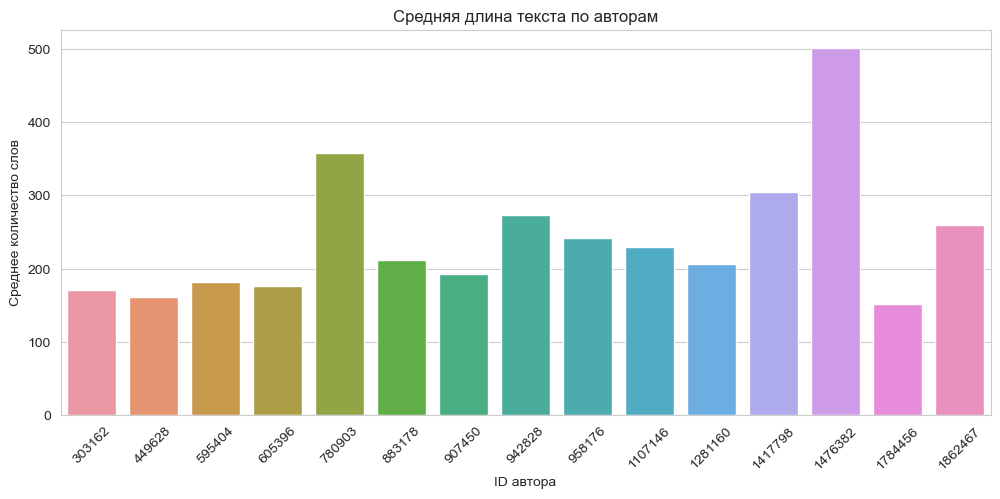

In [12]:
# Визуализируем

plt.figure(figsize=(12, 5))
sns.barplot(data=author_text_stats.reset_index(), x="id", y="mean_word_count")

plt.title("Средняя длина текста по авторам")
plt.xlabel("ID автора")
plt.ylabel("Среднее количество слов")
plt.xticks(rotation=45)
plt.show()

Анализ метаданных: пол, возраст, тема (мы не будем импользовать их для предсказания, но инетресно посмотреть на данные, с которыми мы работаем)

Данные получились хорошо сбалансированными по полу

In [14]:
metadata_cols = ["gender", "age", "topic", "sign"]

for col in metadata_cols:
    if col in df_sample.columns:
        print(f"\nСтолбец: {col}")
        display(df_sample[col].value_counts().head(20))


Столбец: gender


male      7064
female    6181
Name: gender, dtype: int64


Столбец: age


34    1766
35    1766
25    1766
16    1766
38     883
48     883
36     883
17     883
24     883
33     883
27     883
Name: age, dtype: int64


Столбец: topic


indUnk        7064
Student       2649
Fashion        883
Non-Profit     883
Technology     883
Publishing     883
Name: topic, dtype: int64


Столбец: sign


Aries          2649
Scorpio        1766
Aquarius       1766
Cancer         1766
Gemini         1766
Virgo           883
Pisces          883
Libra           883
Sagittarius     883
Name: sign, dtype: int64

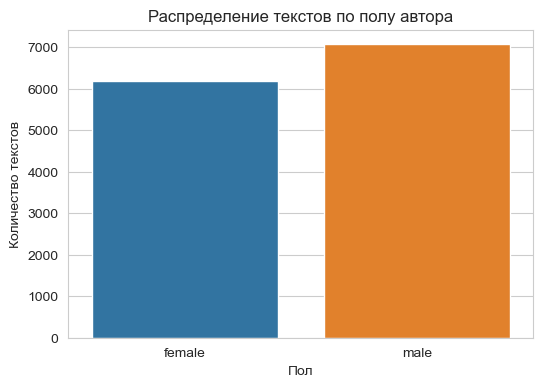

In [95]:
# Визуализируем распределение текстов по полу автора

plt.figure(figsize=(6, 4))
sns.countplot(data=df_sample, x="gender")

plt.title("Распределение текстов по полу автора")
plt.xlabel("Пол")
plt.ylabel("Количество текстов")
plt.show()

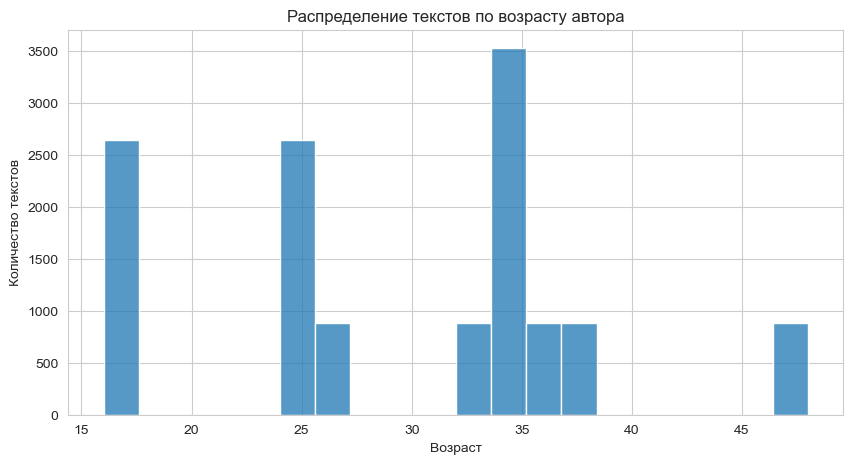

In [16]:
# Распределение текстов по возрасту автора

plt.figure(figsize=(10, 5))
sns.histplot(df_sample["age"], bins=20)

plt.title("Распределение текстов по возрасту автора")
plt.xlabel("Возраст")
plt.ylabel("Количество текстов")
plt.show()

Темы не очень показательный признак, т.к. большинство — unknown

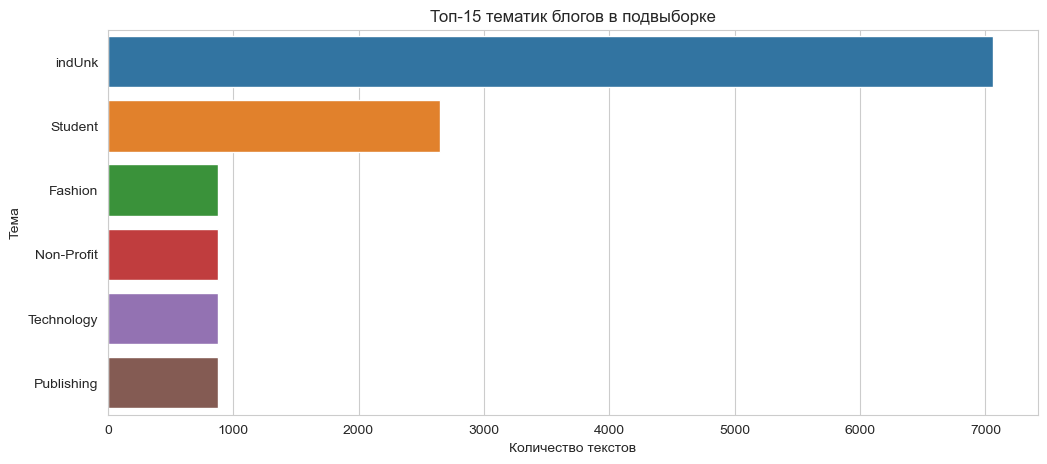

In [96]:
# Топ-15 тематик блогов в подвыборке
top_topics = df_sample["topic"].value_counts().head(15)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_topics.values, y=top_topics.index)
plt.title("Топ-15 тематик блогов в подвыборке")
plt.xlabel("Количество текстов")
plt.ylabel("Тема")
plt.show() 

Проверяем, как авторы связаны с темами

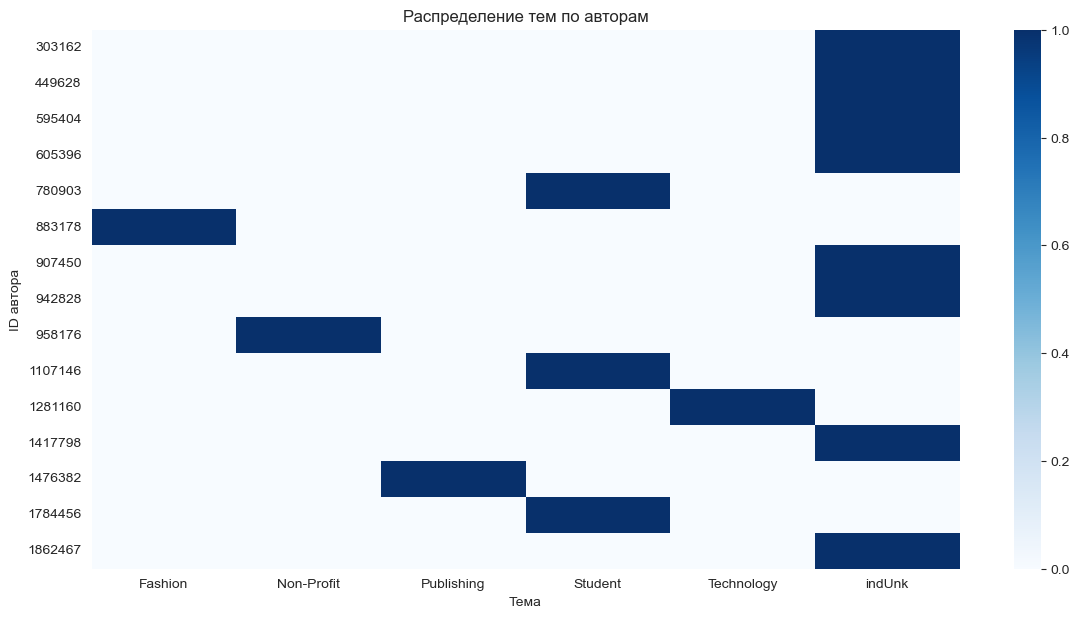

In [17]:
author_topic_table = pd.crosstab(
    df_sample["id"],
    df_sample["topic"],
    normalize="index"
)
plt.figure(figsize=(14, 7))
sns.heatmap(author_topic_table, cmap="Blues")    

plt.title("Распределение тем по авторам")
plt.xlabel("Тема")
plt.ylabel("ID автора")
plt.show()

**Корреляция стилометрических признаков**

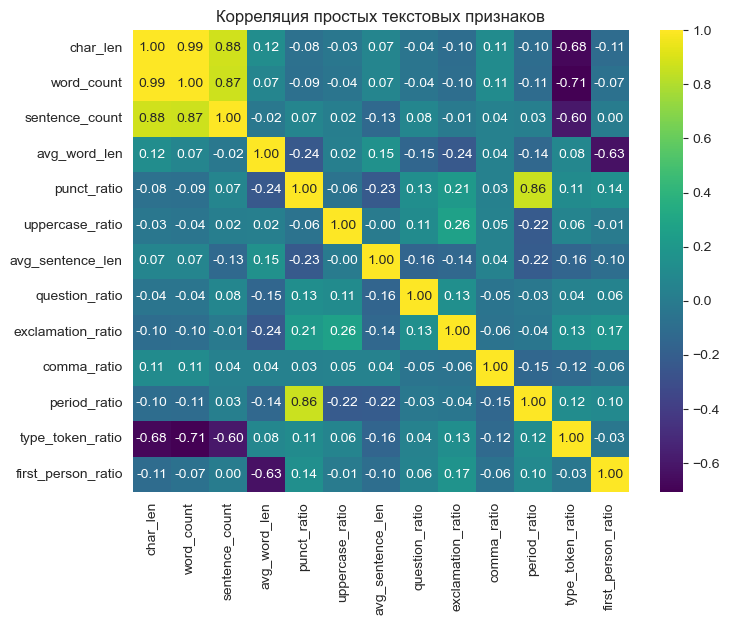

In [18]:
corr = df_sample[text_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="viridis", fmt=".2f")

plt.title("Корреляция простых текстовых признаков")
plt.show()

Из корреляционной матрицы видно, что некоторые признаки коррелируют, поэтому для наших финальных даных отбираем только важные признаки:

* char_len, word_count, sentence_count → оставляем только word_count
* → вместо punct_ratio оставляем более интерпретируемые конкретные знаки пунктуации: question_ratio, exclamation_ratio, comma_ratio, period_ratio

# Preprocessing

In [103]:
# Оставляем сокращённый набор стилометрических признаков
style_features_selected = [
    "word_count",
    "avg_word_len",
    "avg_sentence_len",
    "uppercase_ratio",
    "question_ratio",
    "exclamation_ratio",
    "comma_ratio",
    "period_ratio",
    "type_token_ratio",
    "first_person_ratio"
]

# Целевая переменная — id автора
target_column = "id"

print("Размер финальной таблицы:", df_model.shape)
df_sample.head()

Размер финальной таблицы: (13245, 12)


,id,gender,age,topic,sign,date,text,word_count,char_len,sentence_count,avg_word_len,punct_ratio,uppercase_ratio,avg_sentence_len,question_ratio,exclamation_ratio,comma_ratio,period_ratio,type_token_ratio,first_person_ratio
0,303162,female,38,indUnk,Virgo,"30,May,2004",Funny point of my evening. Mom and I met at my house [I still love to say that ... my house] to measure m...,324,1616,30,3.685185,0.042698,0.040201,10.800000,0.000619,0.002475,0.007426,0.017946,0.521605,0.104938
1,303162,female,38,indUnk,Virgo,"30,May,2004",There. That wasn't so bad. &nbsp; I think the most interesting thing about this interviewing process is fig...,218,1200,25,4.105505,0.045000,0.035754,8.720000,0.000000,0.000833,0.003333,0.020000,0.660550,0.077982
2,303162,female,38,indUnk,Virgo,"30,May,2004",first names only 1. Do a Google search for your first name only 2. Click on 'Images' 3. Pick your favorite...,48,297,5,4.250000,0.037037,0.058824,9.600000,0.000000,0.000000,0.003367,0.023569,0.791667,0.020833
3,303162,female,38,indUnk,Virgo,"30,May,2004",I've spent this afternoon finishing urlLink Bookends . I decided earlier in the week to give myself a reprie...,102,550,6,4.058824,0.021818,0.045894,17.000000,0.000000,0.000000,0.001818,0.010909,0.725490,0.088235
4,303162,female,38,indUnk,Virgo,"30,May,2004","It's time for the Friday Five (on Thursday!): 1. What cologne or perfume do you wear? Poeme by Lancome,...",135,733,19,3.814815,0.055935,0.052427,7.105263,0.006821,0.002729,0.005457,0.016371,0.696296,0.044444


text_raw будем использовать для стилометрии, потому что там важны пунктуация, заглавные буквы и т.п. 

text_clean будем использовать для TF-IDF.

In [107]:
df_prep = df_sample.copy()
df_prep["text_raw"] = df_prep["text"].astype(str)

In [108]:
# Функция для очистки текста

def clean_text(text):
    text = str(text)

    # Нижний регистр
    text = text.lower()

    # Удаляем HTML-теги
    text = re.sub(r"<.*?>", " ", text)

    # Удаляем ссылки
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Удаляем цифры
    text = re.sub(r"\d+", " ", text)

    # Оставляем только английские буквы и пробелы
    text = re.sub(r"[^a-z\s]", " ", text)

    # Убираем лишние пробелы
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [109]:
df_prep["text_clean"] = df_prep["text_raw"].apply(clean_text)
df_prep[["text_raw", "text_clean"]].head()

,text_raw,text_clean
0,Funny point of my evening. Mom and I met at my house [I still love to say that ... my house] to measure m...,funny point of my evening mom and i met at my house i still love to say that my house to measure my windows for a sa...
1,There. That wasn't so bad. &nbsp; I think the most interesting thing about this interviewing process is fig...,there that wasn t so bad nbsp i think the most interesting thing about this interviewing process is figuring out whi...
2,first names only 1. Do a Google search for your first name only 2. Click on 'Images' 3. Pick your favorite...,first names only do a google search for your first name only click on images pick your favorite from the first page ...
3,I've spent this afternoon finishing urlLink Bookends . I decided earlier in the week to give myself a reprie...,i ve spent this afternoon finishing urllink bookends i decided earlier in the week to give myself a reprieve and jus...
4,"It's time for the Friday Five (on Thursday!): 1. What cologne or perfume do you wear? Poeme by Lancome,...",it s time for the friday five on thursday what cologne or perfume do you wear poeme by lancome coco by chanel but i ...


In [110]:
# Считаем количество слов в очищенном тексте

df_prep["clean_word_count"] = df_prep["text_clean"].str.split().apply(len)
df_prep["clean_word_count"].describe()

count    13245.000000
mean       241.472480
std        267.232118
min         40.000000
25%         93.000000
50%        159.000000
75%        285.000000
max       5339.000000
Name: clean_word_count, dtype: float64

Проверяем баланс классов (выборка хорошо сбалансированная)

In [27]:
author_counts_after_prep = df_prep["id"].value_counts().sort_index()
author_counts_after_prep

303162     883
449628     883
595404     883
605396     883
780903     883
883178     883
907450     883
942828     883
958176     883
1107146    883
1281160    883
1417798    883
1476382    883
1784456    883
1862467    883
Name: id, dtype: int64

Сохраняем/открываем предобработанную выборку

In [28]:
path = "blog_authorship_15_authors_preprocessed.csv"

# df_prep.to_csv(path, index=False)

df_prep = pd.read_csv(path)
df_prep

,id,gender,age,topic,sign,date,text,word_count,char_len,sentence_count,avg_word_len,punct_ratio,uppercase_ratio,avg_sentence_len,question_ratio,exclamation_ratio,comma_ratio,period_ratio,type_token_ratio,first_person_ratio,text_raw,text_clean,clean_word_count
0,303162,female,38,indUnk,Virgo,"30,May,2004",Funny point of my evening. Mom and I met at my house [I still love to say that ... my house] to measure m...,324,1616,30,3.685185,0.042698,0.040201,10.800000,0.000619,0.002475,0.007426,0.017946,0.521605,0.104938,Funny point of my evening. Mom and I met at my house [I still love to say that ... my house] to measure m...,funny point of my evening mom and i met at my house i still love to say that my house to measure my windows for a sa...,324
1,303162,female,38,indUnk,Virgo,"30,May,2004",There. That wasn't so bad. &nbsp; I think the most interesting thing about this interviewing process is fig...,218,1200,25,4.105505,0.045000,0.035754,8.720000,0.000000,0.000833,0.003333,0.020000,0.660550,0.077982,There. That wasn't so bad. &nbsp; I think the most interesting thing about this interviewing process is fig...,there that wasn t so bad nbsp i think the most interesting thing about this interviewing process is figuring out whi...,218
2,303162,female,38,indUnk,Virgo,"30,May,2004",first names only 1. Do a Google search for your first name only 2. Click on 'Images' 3. Pick your favorite...,48,297,5,4.250000,0.037037,0.058824,9.600000,0.000000,0.000000,0.003367,0.023569,0.791667,0.020833,first names only 1. Do a Google search for your first name only 2. Click on 'Images' 3. Pick your favorite...,first names only do a google search for your first name only click on images pick your favorite from the first page ...,48
3,303162,female,38,indUnk,Virgo,"30,May,2004",I've spent this afternoon finishing urlLink Bookends . I decided earlier in the week to give myself a reprie...,102,550,6,4.058824,0.021818,0.045894,17.000000,0.000000,0.000000,0.001818,0.010909,0.725490,0.088235,I've spent this afternoon finishing urlLink Bookends . I decided earlier in the week to give myself a reprie...,i ve spent this afternoon finishing urllink bookends i decided earlier in the week to give myself a reprieve and jus...,102
4,303162,female,38,indUnk,Virgo,"30,May,2004","It's time for the Friday Five (on Thursday!): 1. What cologne or perfume do you wear? Poeme by Lancome,...",135,733,19,3.814815,0.055935,0.052427,7.105263,0.006821,0.002729,0.005457,0.016371,0.696296,0.044444,"It's time for the Friday Five (on Thursday!): 1. What cologne or perfume do you wear? Poeme by Lancome,...",it s time for the friday five on thursday what cologne or perfume do you wear poeme by lancome coco by chanel but i ...,135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13240,1862467,female,27,indUnk,Cancer,"17,July,2004","urlLink The New York Times > Arts > Art & Design > Karma? Top Floor, Next to Shoes : 'Stalled in a cab one e...",229,1443,12,4.812227,0.031185,0.045086,19.083333,0.000693,0.000000,0.013860,0.009009,0.676856,0.000000,"urlLink The New York Times > Arts > Art & Design > Karma? Top Floor, Next to Shoes : 'Stalled in a cab one e...",urllink the new york times arts art design karma top floor next to shoes stalled in a cab one evening in the busines...,232
13241,1862467,female,27,indUnk,Cancer,"03,March,2004",This NYT article is especially troubling considering HISD has molded their gifted 'Vanguard' program into the...,334,2181,16,5.185629,0.027052,0.031755,20.875000,0.000000,0.000000,0.010546,0.008253,0.571856,0.008982,This NYT article is especially troubling considering HISD has molded their gifted 'Vanguard' program into the...,this nyt article is especially troubling considering hisd has molded their gifted vanguard program into the college ...,334
13242,1862467,female,27,indUnk,Cancer,"29,April,2004",John and I have come to feel that we made a big mistake in our parenting method and now we're trying to recti...,744,3

# Делим на train/test

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
X = df_prep[
    [
        "text_raw",
        "text_clean",
        "word_count",
        "avg_word_len",
        "avg_sentence_len",
        "uppercase_ratio",
        "question_ratio",
        "exclamation_ratio",
        "comma_ratio",
        "period_ratio",
        "type_token_ratio",
        "first_person_ratio"
    ]
]

y = df_prep["id"]

print("Размер X:", X.shape)
print("Размер y:", y.shape)
print("Количество авторов:", y.nunique())

Размер X: (13245, 12)
Размер y: (13245,)
Количество авторов: 15


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y
)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

print("\nРаспределение авторов в train:")
print(y_train.value_counts().sort_index())

print("\nРаспределение авторов в test:")
print(y_test.value_counts().sort_index())

Размер X_train: (10596, 12)
Размер X_test: (2649, 12)

Распределение авторов в train:
303162     707
449628     706
595404     706
605396     706
780903     706
883178     707
907450     706
942828     706
958176     707
1107146    707
1281160    706
1417798    707
1476382    706
1784456    707
1862467    706
Name: id, dtype: int64

Распределение авторов в test:
303162     176
449628     177
595404     177
605396     177
780903     177
883178     176
907450     177
942828     177
958176     176
1107146    176
1281160    177
1417798    176
1476382    177
1784456    176
1862467    177
Name: id, dtype: int64


# Модели

In [111]:
#pip install gensim

In [33]:
# Импорты для всех моделей

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

from gensim.models import FastText

C:\Users\User\anaconda3\lib\site-packages\requests\__init__.py:109: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(


**Выбор метрик**

Для оценки качества моделей будем использовать стандартные метрики Accuracy, Macro Precision, Macro Recall и Macro F1.

* Accuracy
$$
\frac{TP + TN}{TP + TN + FP + FN}
$$

— показывает общую долю правильных предсказаний среди всех текстов.

* Precision
$$
\frac{TP}{TP + FP}
$$

— показывает, насколько правильно предсказывает модель для каждого автора.

* Recall
$$
\frac{TP}{TP + FN}
$$

— показывает, какую долю текстов автора модель распознала как тексты именно этого автора.

* F1-score
$$
2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

— объединяет Precision и Recall в одну метрику: точность предсказаний + полнота нахождения классов.

→ Macro-averaging

Так как задача многоклассовая, Precision, Recall и F1-score сначала считаются отдельно для каждого автора, а затем усредняются: каждый автор получает одинаковый вес в итоговой метрике независимо от количества текстов.

**Функция для оценки и вывода метрик**

(чтобы не писать ее каждый раз для каждой из моделей, выносим сюда)

In [34]:
# Считаем основные метрики и возвращаем строку для итоговой таблицы results

def evaluate_model(model_name, features_name, y_true, y_pred):
    return {
        "model": model_name,
        "features": features_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

In [35]:
# Это чтобы печатать метрики в одинаковом формате

def print_model_result(result):
    print(result["model"])
    print("Accuracy:", round(result["accuracy"], 4))
    print("Macro Precision:", round(result["macro_precision"], 4))
    print("Macro Recall:", round(result["macro_recall"], 4))
    print("Macro F1:", round(result["macro_f1"], 4))

## Baseline: TF-IDF + Logistic Regression

Это базовая модель

1. сначала выполняется TF-IDF-векторизация 

TF-IDF рассчитывается по формуле:

$$
TFIDF(t, d) = TF(t, d) \times IDF(t)
$$

Что означают буквы:
* t — слово;
* d — документ;
* TF:  частота термина для слова t в документе d (вычисляется как количество вхождений конкретного слова t в документ d, делённое на общее количество слов в документе)
* IDF: обратная частота термина (вычисляется как количество всех документов, поделить на количество документов, в которых содержится интересующее слово)

→ то есть высокий вес получают слова, которые часто встречаются в конкретном тексте, но редко встречаются во всём корпусе

2. признаки подаются в Logistic Regression, модель оценивает вероятность принадлежности текста каждому автору (и выбирает класс с максимально большой вероятностью)

Для многоклассовой классификации используется обобщение логистической регрессии через softmax:

$$
P(y = k \mid x) = \frac{e^{w_k^T x + b_k}}{\sum_{j=1}^{K} e^{w_j^T x + b_j}}
$$

Что означают буквы:
* K — количество классов, то есть авторов;
* k — конкретный класс;
* $(w_k)$ и $(b_k)$ — параметры модели для класса k.
* $w_k^T x + b_k$ — линейная оценка (которая вычисляется для каждого класса)
* $P(y = k \mid x)$ — функция софтмакс

→ итоговый класс выбирается как класс с максимальной вероятностью.

In [317]:
# Для перезапуска: чтобы можно было очистить таблицу результатов

#results = pd.DataFrame(columns=[
#   "model",
 #   "features",
 #   "accuracy",
  #  "macro_precision",
 #   "macro_recall",
 #   "macro_f1"
#])

results

,model,features,accuracy,macro_precision,macro_recall,macro_f1


In [318]:
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            stop_words="english"
        )
    ),
    (
        "logreg",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    )
])

In [319]:
# Обучаем

baseline_model.fit(X_train["text_clean"], y_train)

,steps,"[('tfidf', ...), ('logreg', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [320]:
# Получаем предсказания

baseline_pred = baseline_model.predict(X_test["text_clean"])

In [321]:
# Считаем метрики

baseline_result = evaluate_model(
    model_name="Baseline: TF-IDF + Logistic Regression",
    features_name="TF-IDF",
    y_true=y_test,
    y_pred=baseline_pred
)

print_model_result(baseline_result)

Baseline: TF-IDF + Logistic Regression
Accuracy: 0.7761
Macro Precision: 0.7781
Macro Recall: 0.7758
Macro F1: 0.7757


In [322]:
# Выводим подробно

print(classification_report(y_test, baseline_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.71      0.82      0.76       176
      449628       0.76      0.72      0.74       177
      595404       0.88      0.97      0.92       177
      605396       0.81      0.82      0.81       177
      780903       0.92      0.81      0.86       177
      883178       0.82      0.83      0.82       176
      907450       0.92      0.88      0.90       177
      942828       0.95      0.92      0.93       177
      958176       0.21      0.22      0.22       176
     1107146       0.18      0.16      0.17       176
     1281160       0.95      0.89      0.92       177
     1417798       0.99      0.89      0.94       176
     1476382       0.89      0.93      0.91       177
     1784456       0.96      0.95      0.95       176
     1862467       0.72      0.82      0.77       177

    accuracy                           0.78      2649
   macro avg       0.78      0.78      0.78      2649
weighted avg       0.78   

In [323]:
# Сохраняем в таблицу, чтобы потом сравнивать с другими моделями

results = pd.DataFrame([baseline_result])
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737


Метрики уже достаточно неплохие, но попробуем улучшить.

## Model 1: Improved TF-IDF + Logistic Regression.

Подбираем параметры и улучшаем векторизацию текста:

* добавляем биграммы: *ngram_range=(1, 2);*
* увеличиваем словарь: *max_features=20000;*
* убираем слишком редкие слова: *min_df=2;*
* ограничиваем слишком частые слова: *max_df=0.9*

Также добавляем регуляризацию (C=2) в логистическую регрессию и увеличиваем *max_iter=2000*

In [324]:
model_1 = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,   # увеличиваем количество признаков
            ngram_range=(1, 2),    # используем униграммы и биграммы
            min_df=2,              # слово/фраза должны встретиться минимум в 2 текстах
            max_df=0.9,            # убираем слишком частотные слова (встречаются чаще чем в 90% текстов)
        )
    ),
    (
        "logreg",
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_SEED,
            C=2, # добавляем регуляризацию
            n_jobs=-1
        )
    )
])

In [325]:
model_1.fit(X_train["text_clean"], y_train)

,steps,"[('tfidf', ...), ('logreg', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [326]:
model_1_pred = model_1.predict(X_test["text_clean"])

In [327]:
model_1_result = evaluate_model(
    model_name="Model 1: Improved TF-IDF + Logistic Regression",
    features_name="Improved TF-IDF",
    y_true=y_test,
    y_pred=model_1_pred
)

print_model_result(model_1_result)

Model 1: Improved TF-IDF + Logistic Regression
Accuracy: 0.8007
Macro Precision: 0.8024
Macro Recall: 0.8003
Macro F1: 0.8009


In [328]:
print(classification_report(y_test, model_1_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.76      0.81      0.79       176
      449628       0.81      0.81      0.81       177
      595404       0.97      0.97      0.97       177
      605396       0.83      0.89      0.86       177
      780903       0.95      0.89      0.92       177
      883178       0.84      0.82      0.83       176
      907450       0.89      0.94      0.91       177
      942828       0.94      0.94      0.94       177
      958176       0.19      0.18      0.18       176
     1107146       0.20      0.20      0.20       176
     1281160       0.97      0.90      0.93       177
     1417798       0.99      0.92      0.96       176
     1476382       0.89      0.92      0.91       177
     1784456       0.97      0.96      0.97       176
     1862467       0.83      0.85      0.84       177

    accuracy                           0.80      2649
   macro avg       0.80      0.80      0.80      2649
weighted avg       0.80   

In [329]:
results = pd.concat([results, pd.DataFrame([model_1_result])], ignore_index=True)
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934


Получили улучшение: качество выросло на 0,33 по каждой из метрик

## Model 2. TF-IDF + Linear SVM

1. TF-IDF
Берем параметры из первой модели, так как там получили прирост качества.

2. Linear SVM
— линейный метод классификации, который строит прямую или гиперплоскость, разделяющую классы с максимальным расстоянием.

Для бинарной классификации используется формула:

$$
f(x) = w^T x + b
$$

где:
- \(x\) — вектор признаков текста;
- \(w\) — вектор весов модели;
- \(b\) — свободный коэффициент.

Класс определяется по знаку: если значение функции положительное, объект относится к одному классу, если отрицательное — к другому.

In [330]:
model_2 = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,   
            ngram_range=(1, 2),    
            min_df=2,              
            max_df=0.9,         
        )
    ),
    (
        "svm",
        LinearSVC(
            random_state=RANDOM_SEED
        )
    )
])

In [331]:
model_2.fit(X_train["text_clean"], y_train)

,steps,"[('tfidf', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [332]:
model_2_pred = model_2.predict(X_test["text_clean"])

In [333]:
model_2_result = evaluate_model(
    model_name="Model 2: TF-IDF + Linear SVM",
    features_name="TF-IDF",
    y_true=y_test,
    y_pred=model_2_pred
)

print_model_result(model_2_result)

Model 2: TF-IDF + Linear SVM
Accuracy: 0.8177
Macro Precision: 0.8158
Macro Recall: 0.8173
Macro F1: 0.8163


In [334]:
print(classification_report(y_test, model_2_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.81      0.87      0.84       176
      449628       0.84      0.84      0.84       177
      595404       0.97      0.98      0.97       177
      605396       0.88      0.89      0.88       177
      780903       0.94      0.94      0.94       177
      883178       0.88      0.82      0.85       176
      907450       0.91      0.93      0.92       177
      942828       0.94      0.95      0.95       177
      958176       0.19      0.19      0.19       176
     1107146       0.19      0.19      0.19       176
     1281160       0.96      0.94      0.95       177
     1417798       0.98      0.95      0.97       176
     1476382       0.94      0.95      0.94       177
     1784456       0.94      0.97      0.95       176
     1862467       0.87      0.85      0.86       177

    accuracy                           0.82      2649
   macro avg       0.82      0.82      0.82      2649
weighted avg       0.82   

In [335]:
results = pd.concat([results, pd.DataFrame([model_2_result])], ignore_index=True)
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934
2,Model 2: TF-IDF + Linear SVM,TF-IDF,0.817667,0.815773,0.817319,0.816340


Получили улучшение: качество в среднем по метрикам повысилось на 0,016

## Model 2 tuned: TF-IDF + Linear SVM

Попрубeем подобрать параметры для второй модели через GridSearchCV

In [336]:
# Создаём pipeline для подбора

svm_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,   
            ngram_range=(1, 2),    
            min_df=2,              
            max_df=0.9,         
        )
    ),
    (
        "svm",
        LinearSVC(
            random_state=RANDOM_SEED
        )
    )
])

In [337]:
# Задаём разные варианты гиперпараметров

param_grid = {
    "tfidf__max_features": [5000, 10000, 15000],
    "tfidf__min_df": [1, 2],
    "svm__C": [0.1, 1, 2]
}


In [338]:
# Запускаем GridSearchCV

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_svm.fit(X_train["text_clean"], y_train)

Fitting 3 folds for each of 18 candidates, totalling 54 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'svm__C': [0.1, 1, ...], 'tfidf__max_features': [5000, 10000, ...], 'tfidf__min_df': [1, 2]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,input,'content'


In [339]:
# Смотрим лучшие параметры (по Macro F1)

print("Лучшие параметры:")
print(grid_svm.best_params_)

print("\nЛучший Macro F1 на кросс-валидации:")
print(round(grid_svm.best_score_, 4))

Лучшие параметры:
{'svm__C': 1, 'tfidf__max_features': 15000, 'tfidf__min_df': 1}

Лучший Macro F1 на кросс-валидации:
0.7935


In [340]:
model_2_tuned_pred = grid_svm.predict(X_test["text_clean"])

In [341]:
model_2_tuned_result = evaluate_model(
    model_name="Model 2 tuned: TF-IDF + Linear SVM",
    features_name="TF-IDF + tuned SVM",
    y_true=y_test,
    y_pred=model_2_tuned_pred
)

print_model_result(model_2_tuned_result)

Model 2 tuned: TF-IDF + Linear SVM
Accuracy: 0.8169
Macro Precision: 0.8155
Macro Recall: 0.8166
Macro F1: 0.8157


In [342]:
print(classification_report(y_test, model_2_tuned_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.80      0.87      0.83       176
      449628       0.84      0.84      0.84       177
      595404       0.98      0.99      0.98       177
      605396       0.85      0.89      0.87       177
      780903       0.95      0.93      0.94       177
      883178       0.89      0.82      0.86       176
      907450       0.92      0.94      0.93       177
      942828       0.95      0.97      0.96       177
      958176       0.19      0.18      0.18       176
     1107146       0.19      0.19      0.19       176
     1281160       0.97      0.93      0.95       177
     1417798       0.98      0.95      0.96       176
     1476382       0.93      0.95      0.94       177
     1784456       0.93      0.97      0.95       176
     1862467       0.87      0.84      0.85       177

    accuracy                           0.82      2649
   macro avg       0.82      0.82      0.82      2649
weighted avg       0.82   

In [343]:
results = pd.concat([results, pd.DataFrame([model_2_tuned_result])], ignore_index=True)
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934
2,Model 2: TF-IDF + Linear SVM,TF-IDF,0.817667,0.815773,0.817319,0.816340
3,Model 2 tuned: TF-IDF + Linear SVM,TF-IDF + tuned SVM,0.816912,0.815452,0.816564,0.815695


Метрики высокие, но улучшения качества по сравнению со второй моделью нет (оно даже стало чуть-чуть ниже).

## Model 3: TF-IDF + Selected Stylometric Features

Попробуем поработать со стилометрическими признаками, которые мы выделили. Добавляем их к лексике (TF-IDF)

Идея:
1. text → векторизуем с помощью TF-IDF
2. stylometric columns → приводим к одному виду с помощью StandardScaler (необходимо масштабиорвать признаки, чтобы сравнивать их)
3. объединяем TF-IDF + стилометрию → используем Logistic Regression

In [344]:
text_column = "text_clean"

preprocessor_model_3 = ColumnTransformer([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,   
            ngram_range=(1, 2),    
            min_df=2,              
            max_df=0.9,         
        ),
        text_column
    ),
    (
        "style",
        StandardScaler(),
        style_features_selected
    )
])

In [345]:
model_3 = Pipeline([
    (
        "preprocessor",
        preprocessor_model_3
    ),
    (
        "logreg",
        LogisticRegression(
            C=2,
            max_iter=2000,
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    )
])

In [346]:
model_3.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('logreg', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('tfidf', ...), ('style', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [347]:
model_3_pred = model_3.predict(X_test)

In [348]:
model_3_result = evaluate_model(
    model_name="Model 3: TF-IDF + Stylometric Features + Logistic Regression",
    features_name="TF-IDF + stylometry",
    y_true=y_test,
    y_pred=model_3_pred
)

print_model_result(model_3_result)

Model 3: TF-IDF + Stylometric Features + Logistic Regression
Accuracy: 0.7795
Macro Precision: 0.7837
Macro Recall: 0.7792
Macro F1: 0.7805


In [349]:
print(classification_report(y_test, model_3_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.75      0.81      0.78       176
      449628       0.83      0.75      0.79       177
      595404       0.94      0.97      0.96       177
      605396       0.79      0.87      0.83       177
      780903       0.88      0.86      0.87       177
      883178       0.86      0.81      0.84       176
      907450       0.91      0.90      0.91       177
      942828       0.94      0.94      0.94       177
      958176       0.17      0.16      0.17       176
     1107146       0.19      0.20      0.20       176
     1281160       0.92      0.84      0.88       177
     1417798       0.98      0.88      0.93       176
     1476382       0.89      0.89      0.89       177
     1784456       0.93      0.91      0.92       176
     1862467       0.78      0.89      0.83       177

    accuracy                           0.78      2649
   macro avg       0.78      0.78      0.78      2649
weighted avg       0.78   

In [350]:
results = pd.concat([results, pd.DataFrame([model_3_result])], ignore_index=True)
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934
2,Model 2: TF-IDF + Linear SVM,TF-IDF,0.817667,0.815773,0.817319,0.816340
3,Model 2 tuned: TF-IDF + Linear SVM,TF-IDF + tuned SVM,0.816912,0.815452,0.816564,0.815695
4,Model 3: TF-IDF + Stylometric Features + Logistic Regression,TF-IDF + stylometry,0.779539,0.783677,0.779203,0.780488


К сожалению, подкоючение стилометрических признаков не дает заметных улучшений относитеьно базовой модели.

## Model 4: Word + Character TF-IDF

1. Character TF-IDF учитывает символьные n-граммы, то есть последовательности символов внутри слов и между словами. Так можно попробовать учесть не только сами слова, но и наиболее часто используемые формы слов (окончания, суффиксы и т.п.). Объединяем его с базовым TF-IDF

2. Используем Linear SVM

In [351]:
model_4 = Pipeline([
    (
        "features",
        FeatureUnion([
            (
                "word_tfidf",
                TfidfVectorizer(
                    analyzer="word",
                    max_features=20000,   
                    ngram_range=(1, 2),    
                    min_df=2,              
                    max_df=0.9
                    )
            ),
            (
                "char_tfidf",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(3, 5),
                    max_features=30000,
                    min_df=2,              
                    max_df=0.9
                )
            )
        ])
    ),
    (
        "svm",
        LinearSVC(
            random_state=RANDOM_SEED
        )
    )
])

In [352]:
model_4.fit(X_train["text_clean"], y_train)

,steps,"[('features', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformer_list,"[('word_tfidf', ...), ('char_tfidf', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,input,'content'
,encoding,'utf-8'


In [353]:
model_4_pred = model_4.predict(X_test["text_clean"])

In [354]:
model_4_result = evaluate_model(
    model_name="Model 4: Word + Character TF-IDF + Linear SVM",
    features_name="Word TF-IDF + Character TF-IDF",
    y_true=y_test,
    y_pred=model_4_pred
)

print_model_result(model_4_result)

Model 4: Word + Character TF-IDF + Linear SVM
Accuracy: 0.818
Macro Precision: 0.8172
Macro Recall: 0.8177
Macro F1: 0.8173


In [355]:
print(classification_report(y_test, model_4_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.83      0.88      0.85       176
      449628       0.84      0.80      0.82       177
      595404       0.96      0.98      0.97       177
      605396       0.87      0.90      0.89       177
      780903       0.93      0.93      0.93       177
      883178       0.87      0.85      0.86       176
      907450       0.92      0.93      0.93       177
      942828       0.96      0.97      0.96       177
      958176       0.18      0.18      0.18       176
     1107146       0.19      0.19      0.19       176
     1281160       0.96      0.94      0.95       177
     1417798       0.98      0.95      0.97       176
     1476382       0.93      0.95      0.94       177
     1784456       0.97      0.97      0.97       176
     1862467       0.85      0.84      0.84       177

    accuracy                           0.82      2649
   macro avg       0.82      0.82      0.82      2649
weighted avg       0.82   

In [356]:
results = pd.concat([results, pd.DataFrame([model_4_result])], ignore_index=True)
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934
2,Model 2: TF-IDF + Linear SVM,TF-IDF,0.817667,0.815773,0.817319,0.816340
3,Model 2 tuned: TF-IDF + Linear SVM,TF-IDF + tuned SVM,0.816912,0.815452,0.816564,0.815695
4,Model 3: TF-IDF + Stylometric Features + Logistic Regression,TF-IDF + stylometry,0.779539,0.783677,0.779203,0.780488
5,Model 4: Word + Character TF-IDF + Linear SVM,Word TF-IDF + Character TF-IDF,0.818045,0.817239,0.817711,0.817314


Лучшая модель! Небольшой прирост качества относительно второй, но все же есть.

## Model 5: FastText embeddings + Logistic Regression

В качестве эксперимента попробуем еще другой способ векторизации.

1. FastText представляет каждое слово как набор символьных n-грамм. Вектор слова — это сумма векторов его частей.

$$
\vec{w} = \sum_{g \in G_w} \vec{z}_g
$$

где:

* $w$ — слово;
* $G_w$ — множество символьных n-грамм, из которых состоит слово $w$;
* $\vec{z}_g$ — вектор n-граммы $g$;
* $\vec{w}$ — итоговый вектор слова.

Вектор всего текста получался как среднее векторов слов

Такой подход должен помочь работать с редкими словами, опечатками (а их должно быть много в текстах блогов) и разными словоформами (+ мы помним по предыдущему эксперименту, что работа с символами помогает).

2. Используем Logistic Regression (я попробовала также Linear SVM, но качество было хуже)

In [155]:
# Токенизация текстов (+ оставляем только слова)

def tokenize_text(text):
    text = str(text).lower()
    tokens = re.findall(r"[a-z]+", text)
    return tokens

In [156]:
X_train_tokens = X_train["text_clean"].apply(tokenize_text)
X_test_tokens = X_test["text_clean"].apply(tokenize_text)

X_train_tokens.head()

7430    [hmm, i, ll, send, you, an, email, just, in, case, heh, it, ain, t, about, stupid, bia, i, don, t, think, i, really,...
8322    [lindsey, we, re, not, thirteen, we, re, actually, more, mature, then, most, girls, our, age, we, re, not, drama, qu...
6210    [the, feast, of, sts, gwynllyw, and, gladys, is, today, there, is, information, on, them, urllink, here, and, urllin...
3935    [book, review, give, me, a, break, by, john, stossel, yes, i, ve, actually, been, studying, but, if, i, spend, a, ch...
1099    [tired, after, spending, a, lot, of, the, night, and, today, getting, the, computer, updated, i, m, feeling, tired, ...
Name: text_clean, dtype: object

In [210]:
# Обучаем
# + провела несолько экспериментов, подбирая параметры вручную; лучшие результаты с такими параметрами:

fasttext_model = FastText(
    sentences=X_train_tokens.tolist(),
    vector_size=300,   # размер векторов
    window=5,          # контекстное окно
    min_count=1,       # оставляем редкие слова
    sg=1,              # skip-gram
    workers=4, # количество потоков для обучения
    epochs=30,  # количество эпох
    seed=RANDOM_SEED
)

In [211]:
# Превращаем один текст в один числовой вектор

def text_to_vector(tokens, model, vector_size=100):
    vectors = []

    for token in tokens:
        if token in model.wv:
            vectors.append(model.wv[token])

    if len(vectors) == 0:
        return np.zeros(vector_size)

    return np.mean(vectors, axis=0)

In [212]:
# Применяем text_to_vector ко всем текстам из train

X_train_fasttext = np.vstack(
    X_train_tokens.apply(
        lambda tokens: text_to_vector(tokens, fasttext_model, vector_size=100)
    )
)

X_test_fasttext = np.vstack(
    X_test_tokens.apply(
        lambda tokens: text_to_vector(tokens, fasttext_model, vector_size=100)
    )
)

print("Размер X_train_fasttext:", X_train_fasttext.shape)
print("Размер X_test_fasttext:", X_test_fasttext.shape)

Размер X_train_fasttext: (10596, 300)
Размер X_test_fasttext: (2649, 300)


In [357]:
model_5 = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

model_5.fit(X_train_fasttext, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [358]:
model_5_pred = model_5.predict(X_test_fasttext)

In [359]:
model_5_result = evaluate_model(
    model_name="Model 5: FastText embeddings + Logistic Regression",
    features_name="FastText embeddings",
    y_true=y_test,
    y_pred=model_5_pred
)

print_model_result(model_5_result)

Model 5: FastText embeddings + Logistic Regression
Accuracy: 0.7595
Macro Precision: 0.7576
Macro Recall: 0.7593
Macro F1: 0.7572


In [360]:
print(classification_report(y_test, model_5_pred, zero_division=0))

              precision    recall  f1-score   support

      303162       0.65      0.68      0.66       176
      449628       0.72      0.64      0.68       177
      595404       0.81      0.90      0.85       177
      605396       0.80      0.82      0.81       177
      780903       0.86      0.86      0.86       177
      883178       0.70      0.76      0.73       176
      907450       0.83      0.85      0.84       177
      942828       0.93      0.90      0.92       177
      958176       0.33      0.27      0.29       176
     1107146       0.38      0.41      0.39       176
     1281160       0.97      0.89      0.93       177
     1417798       0.94      0.90      0.92       176
     1476382       0.80      0.93      0.86       177
     1784456       0.95      0.92      0.94       176
     1862467       0.69      0.66      0.67       177

    accuracy                           0.76      2649
   macro avg       0.76      0.76      0.76      2649
weighted avg       0.76   

In [361]:
results = pd.concat([results, pd.DataFrame([model_5_result])], ignore_index=True)
results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934
2,Model 2: TF-IDF + Linear SVM,TF-IDF,0.817667,0.815773,0.817319,0.816340
3,Model 2 tuned: TF-IDF + Linear SVM,TF-IDF + tuned SVM,0.816912,0.815452,0.816564,0.815695
4,Model 3: TF-IDF + Stylometric Features + Logistic Regression,TF-IDF + stylometry,0.779539,0.783677,0.779203,0.780488
5,Model 4: Word + Character TF-IDF + Linear SVM,Word TF-IDF + Character TF-IDF,0.818045,0.817239,0.817711,0.817314
6,Model 5: FastText embeddings + Logistic Regression,FastText embeddings,0.759532,0.757584,0.759298,0.757207


Качество получилось хуже. Но возможно, стоит еще поподбирать параметры для векторизации: оставим это как гипотезу для продолжения исследования.

# Evaluation

In [311]:
# Итоговая таблица метрик
# Основная метрикой для сравнени — Macro F1.

results.sort_values("macro_f1", ascending=False)

,model,features,accuracy,macro_precision,macro_recall,macro_f1
5,Model 4: Word + Character TF-IDF + Linear SVM,Word TF-IDF + Character TF-IDF,0.818045,0.817239,0.817711,0.817314
2,Model 2: TF-IDF + Linear SVM,TF-IDF,0.817667,0.815773,0.817319,0.816340
3,Model 2 tuned: TF-IDF + Linear SVM,TF-IDF + tuned SVM,0.816912,0.815452,0.816564,0.815695
1,Model 1: Improved TF-IDF + Logistic Regression,Improved TF-IDF,0.800680,0.802449,0.800340,0.800934
4,Model 3: TF-IDF + Stylometric Features + Logistic Regression,TF-IDF + stylometry,0.779539,0.783677,0.779203,0.780488
0,Baseline: TF-IDF + Logistic Regression,TF-IDF,0.776142,0.778115,0.775847,0.775737
6,Model 5: FastText embeddings + Logistic Regression,FastText embeddings,0.759532,0.757584,0.759298,0.757207


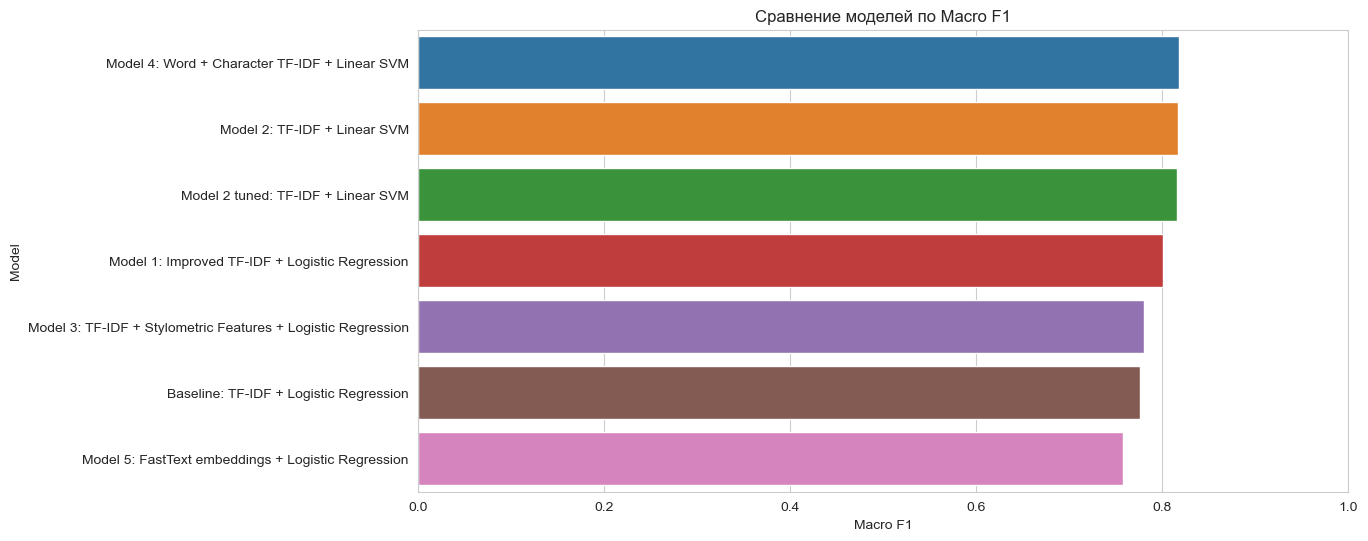

In [225]:
# Визуализируем

results_sorted = results.sort_values("macro_f1", ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=results_sorted, x="macro_f1", y="model")

plt.title("Сравнение моделей по Macro F1")
plt.xlabel("Macro F1")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

Автоматически выбираем лучшую модель по macro_f1


In [226]:
best_model_name = results.sort_values("macro_f1", ascending=False).iloc[0]["model"]

print("Лучшая модель по Macro F1:")
print(best_model_name)

Лучшая модель по Macro F1:
Model 4: Word + Character TF-IDF + Linear SVM


In [228]:
# Предсказания лучшей модели

predictions_dict = {
    "Baseline: TF-IDF + Logistic Regression": baseline_pred,
    "Model 1: Improved TF-IDF + Logistic Regression": model_1_pred,
    "Model 2: TF-IDF + Linear SVM": model_2_pred,
    "Model 2 tuned: TF-IDF + Linear SVM": model_2_tuned_pred,
    "Model 3: TF-IDF + Stylometric Features + Logistic Regression": model_3_pred,
    "Model 4: Word + Character TF-IDF + Linear SVM": model_4_pred,
    "Model 5: FastText embeddings + Logistic Regression": model_5_pred
}

best_pred = predictions_dict[best_model_name]

In [229]:
# Classification report для лучшей модели

from sklearn.metrics import classification_report

print("Classification report for best model:")

report_dict = classification_report(
    y_test,
    best_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T
report_df.round(4)

Classification report for best model:


,precision,recall,f1-score,support
303162,0.8289,0.8807,0.8540,176.000
449628,0.8443,0.7966,0.8198,177.000
595404,0.9613,0.9831,0.9721,177.000
605396,0.8736,0.8983,0.8858,177.000
780903,0.9322,0.9322,0.9322,177.000
883178,0.8721,0.8523,0.8621,176.000
907450,0.9218,0.9322,0.9270,177.000
942828,0.9556,0.9718,0.9636,177.000
958176,0.1802,0.1761,0.1782,176.000
1107146,0.1910,0.1932,0.1921,176.000


Сlassification report позволяет оценить качество классификации отдельно по каждому автору: 

* precision — точность предсказаний автора
* recall — насколько хорошо модель находит тексты этого автора

## Анализ ошибок

По графикам и таблице можно заметить, что есть проблема с двумя конкретными автоами (еоторые модель путает между собой):
**id = 958176** и **id = 1107146** 

Попробуем понять, почему так

In [294]:
# Создаем таличку, чтобы сравнить этих двух авторов по разным признакам

authors_to_compare = [958176, 1107146]
df_two_authors = df_prep[df_prep["id"].isin(authors_to_compare)].copy()

print("Размер подвыборки:", df_two_authors.shape)
print(df_two_authors["id"].value_counts())

Размер подвыборки: (1766, 23)
958176     883
1107146    883
Name: id, dtype: int64


Посмотрим, насколько авторы похожи по разным признакам

In [296]:
df_two_authors[["id", "gender", "age", "topic"]].drop_duplicates().sort_values("id")

,id,gender,age,topic
7064,958176,male,17,Non-Profit
7947,1107146,female,16,Student


Если смотреть по метаданным, то единственная схожесть — возраст

In [301]:
style_features_for_analysis = [
    "word_count",
    "avg_word_len",
    "avg_sentence_len",
    "uppercase_ratio",
    "question_ratio",
    "exclamation_ratio",
    "comma_ratio",
    "period_ratio",
    "type_token_ratio",
    "first_person_ratio"
]

df_two_authors.groupby("id")[style_features_for_analysis].mean().round(4)

,word_count,avg_word_len,avg_sentence_len,uppercase_ratio,question_ratio,exclamation_ratio,comma_ratio,period_ratio,type_token_ratio,first_person_ratio
id,,,,,,,,,,
958176,241.6455,3.8311,13.7233,0.0560,0.0014,0.0022,0.0119,0.0204,0.6510,0.0739
1107146,229.3284,3.8246,13.3476,0.0571,0.0015,0.0022,0.0119,0.0203,0.6556,0.0748


А вот по стилометрическим признакам эти два автора действительно очень схожи: то есть их тексты похожи с формальной точки зрения. Возможно, поэтому модель их путала.

In [312]:
# Посмотрим на их тексты (берем рандомные примеры)

authors_to_show = [958176, 1107146]

for author_id in authors_to_show:
    print(f"Author ID: {author_id}")

    examples = (
        df_prep[df_prep["id"] == author_id]["text_raw"]
        .sample(3, random_state=RANDOM_SEED)
        .tolist()
    )
    for i, text in enumerate(examples, start=1):
        print(f"\nExample {i}:")
        print(text[:1000])

Author ID: 958176

Example 1:
                 Aye lad, that's true. It was quite a random and 'ummm....'ing sort of post.  I was the only one who posted this whole weekend. How irrelevent.  I'm sorry Abby! But it's not that cool. For the majority 'o us, it'll be spent reading supergroovy books and doing nothing. Linds was at...a college. I hesitate to say which one. It was in Kentucky tho...I think?!? Stupid selective memory.  I dun even know how to play Bridge. But that is awesome. You tend to whup up them in everything. Don't you think they'd learn to quit? Abby always wins. And four digit numbers always give me the 'wow that's incredibly high' complex, so tharr be a double bonus.   It's ten 'o clock and I'm tired. Hell...it's horrible to be old.       

Example 2:
                 I was close to doing that Will. This is her way of telling me that I wronged her. I know that we should talk it out but this weekend I have dance, piano, a research paper, and other exams to review for no

Строим Confusion matrix. Она показывает, каких авторов лучшая модель распознаёт правильно, а каких путает между собой.

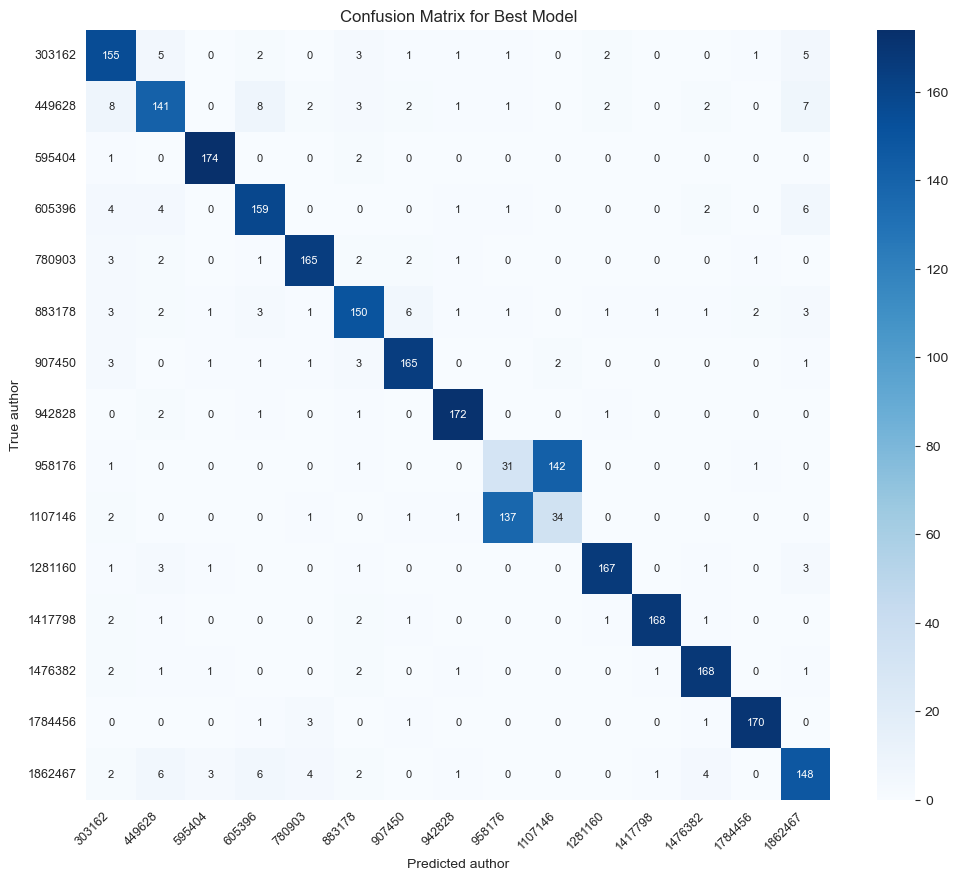

In [230]:
# Confusion matrix

from sklearn.metrics import confusion_matrix

labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, best_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    annot_kws={"size": 8}
)

plt.title("Confusion Matrix for Best Model")
plt.xlabel("Predicted author")
plt.ylabel("True author")

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.show()

**Главный вывод:**

В целом модель 4 работает хорошо (почти у всех авторов тёмные клетки находятся на диагонали, т.е. большинство текстов классифицируется правильно). Здесь снова видим главную проблему: авторы 958176 и 1107146 практически всегда путаются между собой:

* У автора 958176 правильно распознано 35 текстов, а ошибочно предсказано как 1107146 138;
* У автора 1107146 правильно распознано 30 текстов, а ошибочно как 958176 141

Еще на всякий случай проверим, так же путает вторая модель этих двух авторов? (получается, что да)

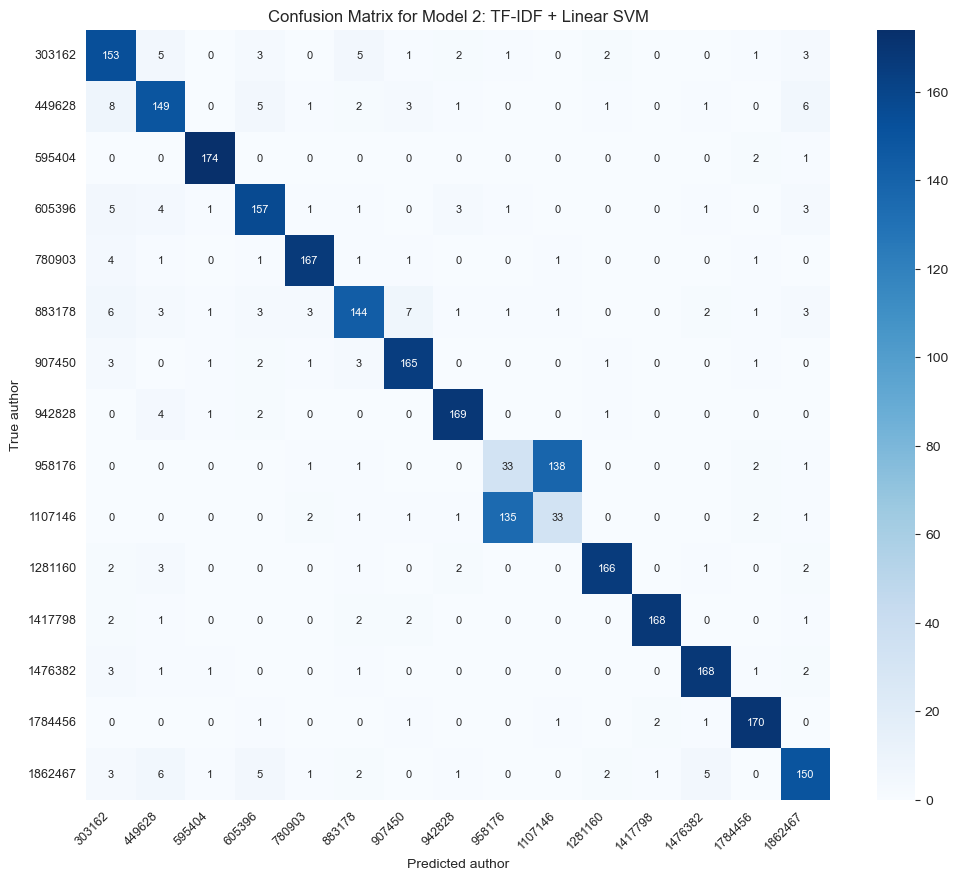

In [313]:
# Confusion matrix для Model 2: TF-IDF + Linear SVM

from sklearn.metrics import confusion_matrix

labels = sorted(y_test.unique())

cm_model_2 = confusion_matrix(y_test, model_2_pred, labels=labels)
cm_model_2_df = pd.DataFrame(cm_model_2, index=labels, columns=labels)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_model_2_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    annot_kws={"size": 8}
)

plt.title("Confusion Matrix for Model 2: TF-IDF + Linear SVM")
plt.xlabel("Predicted author")
plt.ylabel("True author")

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.show()

Посмотрим еще на другие примеры

In [309]:
# Примеры правильных предсказаний

correct_examples = (error_df[error_df["is_correct"] == True].sample(5, random_state=RANDOM_SEED))
correct_examples[["true_author", "predicted_author", "text_raw"]]

,true_author,predicted_author,text_raw
5230,883178,883178,"Angels in America By Duf 'Art Lover' Fer If you have a chance, I urge you, nayI plead with yousee url..."
4619,883178,883178,Tuesday Five: A little slow on the pick-up 1. What is the one thing you don't like about your body...
8602,1107146,1107146,"Ok, pagans are like people who worship the devil, but Josh was wrong on his source. The '3-fold Ru..."
2605,595404,595404,"ok, so mm is reading the red tent, a novel by anita diamant, whose other books include the new jewish wedding..."
10749,1476382,1476382,"Class in New York City Granted , I gave this blog entry a really sexy title because I wanted you to head ..."


In [310]:
# Примеры ошибочных предсказаний

wrong_examples = (error_df[error_df["is_correct"] == False].sample(5, random_state=RANDOM_SEED))
wrong_examples[["true_author", "predicted_author", "text_raw"]]

,true_author,predicted_author,text_raw
12943,1862467,1417798,My favorite part was when a News 2 reporter called into the studio and said he was at Westheimer and Shepherd...
13080,1862467,605396,"I knew Constance was at a technology conference in Maine, and I've heard the whole world of techie bloggers t..."
11594,1784456,907450,"urlLink www.howies.co.uk For the believers of fair trade, organic and pro-environment is... HOWIE..."
8425,1107146,958176,"Ahh, Linds you forget to inform the masses, or at least the people on the BLog, that you and I were..."
7855,958176,1107146,"Sorry, I didn't know if yall had done that yet. But I just checked and it's fixed. You're a geniu..."


# Дополнительный эксперимент: 

Попробуем предсказывать gender

Возьмем лучшую модель: Word + Character TF-IDF + Linear SVM

In [273]:
X_gender = df_prep["text_clean"]
y_gender = df_prep["gender"]

X_gender_train, X_gender_test, y_gender_train, y_gender_test = train_test_split(
    X_gender,
    y_gender,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_gender
)

print("Train size:", X_gender_train.shape)
print("Test size:", X_gender_test.shape)

Train size: (10596,)
Test size: (2649,)


In [274]:
gender_model = Pipeline([
    (
        "features",
        FeatureUnion([
            (
                "word_tfidf",
                TfidfVectorizer(
                    analyzer="word",
                    max_features=20000,
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.9
                )
            ),
            (
                "char_tfidf",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(3, 5),
                    max_features=30000,
                    min_df=2,
                    max_df=0.9
                )
            )
        ])
    ),
    (
        "svm",
        LinearSVC(
            random_state=RANDOM_SEED
        )
    )
])

In [275]:
gender_model.fit(X_gender_train, y_gender_train)

,steps,"[('features', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformer_list,"[('word_tfidf', ...), ('char_tfidf', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,input,'content'
,encoding,'utf-8'


In [276]:
gender_pred = gender_model.predict(X_gender_test)

In [277]:
# Метрики

gender_result = evaluate_model(
    model_name="Gender prediction",
    features_name="Word TF-IDF + Character TF-IDF",
    y_true=y_gender_test,
    y_pred=gender_pred
)

print_model_result(gender_result)

Gender prediction
Accuracy: 0.7897
Macro Precision: 0.7898
Macro Recall: 0.7871
Macro F1: 0.788


In [278]:
print(classification_report(y_gender_test, gender_pred, zero_division=0))

              precision    recall  f1-score   support

      female       0.79      0.75      0.77      1236
        male       0.79      0.83      0.81      1413

    accuracy                           0.79      2649
   macro avg       0.79      0.79      0.79      2649
weighted avg       0.79      0.79      0.79      2649



In [282]:
additional_results = pd.concat([additional_results, pd.DataFrame([gender_result])], ignore_index=True)
additional_results

,model,features,accuracy,macro_precision,macro_recall,macro_f1
0,Gender prediction,Word TF-IDF + Character TF-IDF,0.789732,0.789752,0.787142,0.787962


Качество предсказания пола получилось достаточно высокое. В будущем можно также поэкспериментировать с другими параметрами.

# Выводы

Лучшая модель — модель 4: Word + Character TF-IDF + Linear SVM (Accuracy = 0.818045, Macro F1 = 0.817314)
Она почти идеально предсказывает практически все, но путает между собой двух конкретных авторов — 958176 и 1107146, которые похожи по возрасту и по стилометрическим признакам.

На втором месте — модель 2: TF-IDF + Linear SVM (Accuracy = 0.817667, Macro F1 = 0.815695), а худший результат показала Model 5: FastText embeddings + Logistic Regression (Accuracy = 0.759532, Macro F1 = 0.757207).	

В целом можно сказать, что на наших данных Linear SVM показала более высокие результаты, чем логистическая регрессия a векторизация TF-IDF работала значительно лучше чем FastText. Кроме того, добавление стилометрических признаков не дало прироста качества, а добавление символьного TF-IDF помогло достичь лучшего результата в этом эксперименте.

**Гипотезы, как еще можно попытаться улучшить качество (в дальнейшем)**

1. Более тщательно подбрать параметров как для векториации, так и для логистической регрессии/Linear SVM
2. Снизить влияния темы текста: например посмотреть, как модели предсказывают автора в рамках одной темы (! мы не используем тему как признак модели, но тема может быть явно выражена в тексте через лексику, и тогда модель опирается не на авторский стиль а только на лексику).
3. Увеличить количество текстов каждого автора (но для этого надо брать менше авторов/более короткие тексты)
4. Улучшить отбор стилометрических признаков (возможно, поэкспериментировать с другими) *возможно, кстати, стоит добавить в знаки пунктуации скобочки, потому что они часто используются вместо эмоджи (тем более в 2004 году и ранее)

*5. Не совсем улучшение, но стоит попробовать также предсказывать другие признаки (из метаданных), так как на gender получился достаточно хороший результат